# HW 7 — Gradient Boosting Regression of Cortical Bone Modulus
**BME 5650: Biosolid Mechanics**

**Goal:** predict Young's modulus $E$ (GPa) of cortical bone from two compositional inputs — calcium content $Ca$ (mg/g) and volume fraction $V_f$ — using a model that does **not** assume a physical form a priori: scikit-learn's `GradientBoostingRegressor` (GBR).

Workflow
1. Load and clean the data
2. 75:25 train/test split
3. Baseline: Currey-type 3-parameter power law $E = a\,Ca^{b}\,V_f^{c}$ (the physical model from class)
4. Gradient boosting: default fit, hyperparameter tuning by 5-fold cross-validation
5. Model quality on held-out data (RMSE, MAE, $R^2$) and diagnostic plots
6. Effect of each hyperparameter on RMSE and $R^2$
7. Interpretation: feature importance and partial dependence (compare with Currey)
8. Does normalization matter?
9. Behaviour far outside the data range

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import curve_fit

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

SEED = 42
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

def metrics(y, yhat):
    return {"RMSE (GPa)": np.sqrt(mean_squared_error(y, yhat)),
            "MAE (GPa)": mean_absolute_error(y, yhat),
            "R2": r2_score(y, yhat)}

## 1. Load and clean the data

In [2]:
df = pd.read_csv("bone_composition_modulus_final.csv")
print(df.shape)
print(df.isna().sum())
df.describe().round(3)

(370, 5)
E_GPa             0
Ca_mg_g           0
Vf                1
source_row        0
E_GPa_original    0
dtype: int64


,E_GPa,Ca_mg_g,Vf,source_row,E_GPa_original
count,370.000,370.000,369.000,370.000,370.000
mean,16.878,261.907,0.905,194.519,16.903
std,7.866,28.334,0.076,110.697,7.710
min,0.975,186.942,0.611,3.000,1.097
25%,10.157,243.965,0.878,97.250,10.269
50%,17.094,263.173,0.934,195.500,17.978
75%,21.636,278.838,0.959,289.500,20.887
max,41.415,334.822,0.995,384.000,34.147


One sample is missing $V_f$. Gradient boosting in scikit-learn can handle NaN natively only in `HistGradientBoostingRegressor`, and the power-law baseline cannot use it at all, so the row is dropped (369 samples remain). The target is `E_GPa`; `source_row` and `E_GPa_original` are bookkeeping columns and are **not** used as inputs.

Samples used: 369


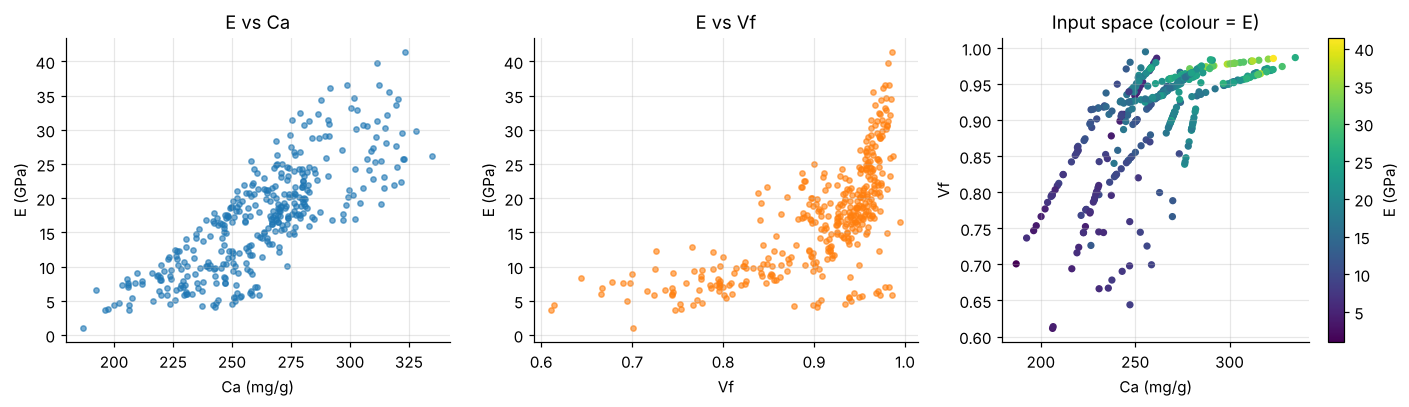

,E_GPa,Ca_mg_g,Vf
E_GPa,1.000,0.806,0.676
Ca_mg_g,0.806,1.000,0.681
Vf,0.676,0.681,1.000


In [3]:
df = df.dropna(subset=["Vf"]).reset_index(drop=True)
features = ["Ca_mg_g", "Vf"]
X = df[features].values
y = df["E_GPa"].values
print("Samples used:", len(df))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].scatter(df.Ca_mg_g, df.E_GPa, s=12, alpha=.6); ax[0].set(xlabel="Ca (mg/g)", ylabel="E (GPa)", title="E vs Ca")
ax[1].scatter(df.Vf, df.E_GPa, s=12, alpha=.6, color="C1"); ax[1].set(xlabel="Vf", ylabel="E (GPa)", title="E vs Vf")
sc = ax[2].scatter(df.Ca_mg_g, df.Vf, c=df.E_GPa, s=14, cmap="viridis")
ax[2].set(xlabel="Ca (mg/g)", ylabel="Vf", title="Input space (colour = E)"); fig.colorbar(sc, ax=ax[2], label="E (GPa)")
fig.tight_layout(); fig.savefig(FIG/"01_data.png", dpi=200); plt.show()
df[["E_GPa", "Ca_mg_g", "Vf"]].corr().round(3)

## 2. Train/test split (75:25)

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=SEED)
print(f"Train: {len(y_tr)}   Test: {len(y_te)}")

Train: 276   Test: 93


## 3. Baseline: Currey-type physical model
$E = a\,Ca^{b}\,V_f^{c}$, fitted by nonlinear least squares (`scipy.optimize.curve_fit`) on the training set only.

In [5]:
def currey(Xc, a, b, c):
    Ca, Vf = Xc
    return a * Ca**b * Vf**c

p_cur, _ = curve_fit(currey, (X_tr[:, 0], X_tr[:, 1]), y_tr, p0=[1e-5, 2.5, 2.5], maxfev=20000)
print("a = %.3e, b = %.3f, c = %.3f" % tuple(p_cur))
cur_tr = currey((X_tr[:, 0], X_tr[:, 1]), *p_cur)
cur_te = currey((X_te[:, 0], X_te[:, 1]), *p_cur)
pd.DataFrame({"train": metrics(y_tr, cur_tr), "test": metrics(y_te, cur_te)}).T.round(3)

a = 4.361e-05, b = 2.348, c = 2.626


,RMSE (GPa),MAE (GPa),R2
train,4.296,3.228,0.705
test,4.502,3.404,0.655


## 4. Gradient Boosting Regressor
### 4a. Default hyperparameters
Defaults: `n_estimators=100, learning_rate=0.1, max_depth=3, subsample=1.0, loss='squared_error'`.

In [6]:
gbr0 = GradientBoostingRegressor(random_state=SEED).fit(X_tr, y_tr)
pd.DataFrame({"train": metrics(y_tr, gbr0.predict(X_tr)),
              "test": metrics(y_te, gbr0.predict(X_te))}).T.round(3)

,RMSE (GPa),MAE (GPa),R2
train,2.22,1.692,0.921
test,4.23,3.084,0.696


### 4b. Hyperparameter tuning — `GridSearchCV`, 5-fold CV on the **training set only**
The test set is never seen during tuning, so the test metrics remain an honest estimate of generalisation.

In [7]:
param_grid = {
    "n_estimators":     [50, 100, 200, 400],
    "learning_rate":    [0.01, 0.05, 0.1, 0.2],
    "max_depth":        [1, 2, 3, 4],
    "min_samples_leaf": [1, 5, 10],
    "subsample":        [0.7, 1.0],
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(GradientBoostingRegressor(random_state=SEED), param_grid, cv=cv,
                    scoring="neg_root_mean_squared_error", n_jobs=-1)
grid.fit(X_tr, y_tr)
print("Best params:", grid.best_params_)
print("Best CV RMSE: %.3f GPa" % -grid.best_score_)
cv_res = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
cv_res[["param_n_estimators", "param_learning_rate", "param_max_depth",
        "param_min_samples_leaf", "param_subsample", "mean_test_score", "std_test_score"]].head(10)

Best params: {'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 10, 'n_estimators': 100, 'subsample': 0.7}
Best CV RMSE: 4.064 GPa


,param_n_estimators,param_learning_rate,param_max_depth,param_min_samples_leaf,param_subsample,mean_test_score,std_test_score
234,100,0.10,2,10,0.7,-4.064237,0.295893
258,100,0.10,3,10,0.7,-4.074014,0.294041
236,200,0.10,2,10,0.7,-4.076154,0.272785
140,200,0.05,2,10,0.7,-4.079420,0.301902
328,50,0.20,2,10,0.7,-4.080400,0.271686
138,100,0.05,2,10,0.7,-4.081078,0.348918
232,50,0.10,2,10,0.7,-4.081452,0.337399
46,400,0.01,2,10,0.7,-4.082712,0.361019
162,100,0.05,3,10,0.7,-4.087740,0.303060
70,400,0.01,3,10,0.7,-4.094714,0.356319


## 5. Final model quality on the held-out test set

In [8]:
gbr = grid.best_estimator_
p_tr, p_te = gbr.predict(X_tr), gbr.predict(X_te)
summary = pd.DataFrame({
    ("Currey power law", "train"): metrics(y_tr, cur_tr),
    ("Currey power law", "test"):  metrics(y_te, cur_te),
    ("GBR default", "train"): metrics(y_tr, gbr0.predict(X_tr)),
    ("GBR default", "test"):  metrics(y_te, gbr0.predict(X_te)),
    ("GBR tuned", "train"): metrics(y_tr, p_tr),
    ("GBR tuned", "test"):  metrics(y_te, p_te),
}).T.round(3)
summary.to_csv(FIG/"summary_metrics.csv")
summary

RMSE (GPa)  MAE (GPa)     R2
Currey power law train       4.296      3.228  0.705
                 test        4.502      3.404  0.655
GBR default      train       2.220      1.692  0.921
                 test        4.230      3.084  0.696
GBR tuned        train       3.197      2.388  0.837
                 test        4.132      3.032  0.710

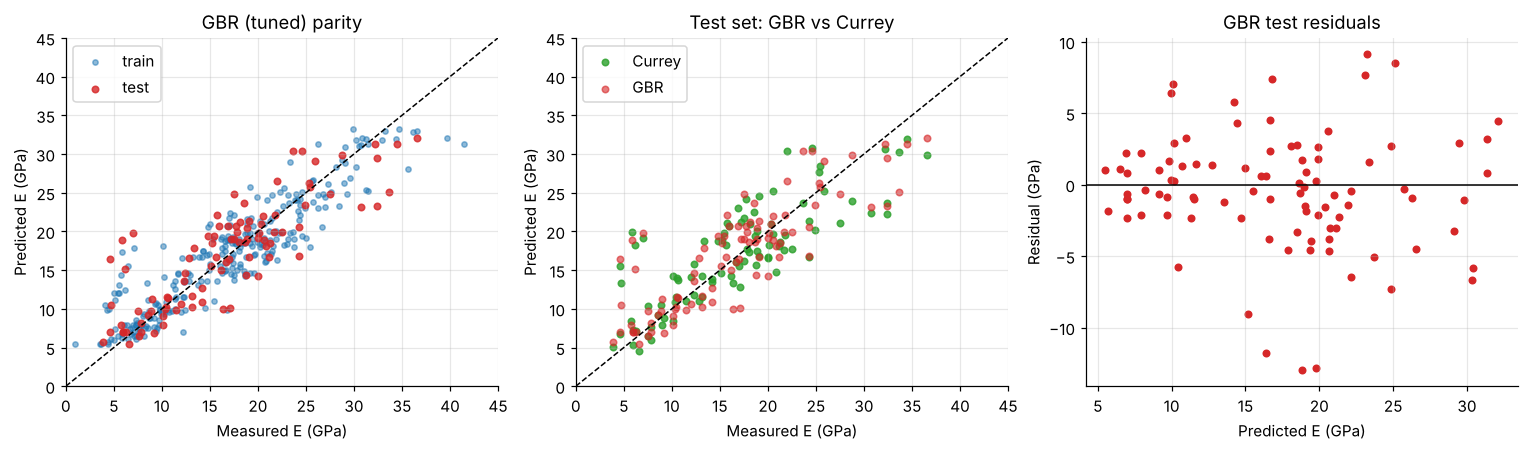

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
lim = [0, 45]
ax[0].scatter(y_tr, p_tr, s=12, alpha=.5, label="train")
ax[0].scatter(y_te, p_te, s=18, alpha=.8, label="test", color="C3")
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set(xlim=lim, ylim=lim, xlabel="Measured E (GPa)", ylabel="Predicted E (GPa)",
          title="GBR (tuned) parity"); ax[0].legend()
ax[1].scatter(y_te, cur_te, s=18, alpha=.8, color="C2", label="Currey")
ax[1].scatter(y_te, p_te, s=18, alpha=.6, color="C3", label="GBR")
ax[1].plot(lim, lim, "k--", lw=1); ax[1].set(xlim=lim, ylim=lim, xlabel="Measured E (GPa)", ylabel="Predicted E (GPa)",
          title="Test set: GBR vs Currey"); ax[1].legend()
ax[2].scatter(p_te, y_te - p_te, s=18, color="C3"); ax[2].axhline(0, color="k", lw=1)
ax[2].set(xlabel="Predicted E (GPa)", ylabel="Residual (GPa)", title="GBR test residuals")
fig.tight_layout(); fig.savefig(FIG/"02_parity_residuals.png", dpi=200); plt.show()

### Learning curve over boosting iterations
`staged_predict` gives the prediction after every added tree — showing how training error keeps falling while test error plateaus (the over-fitting signature).

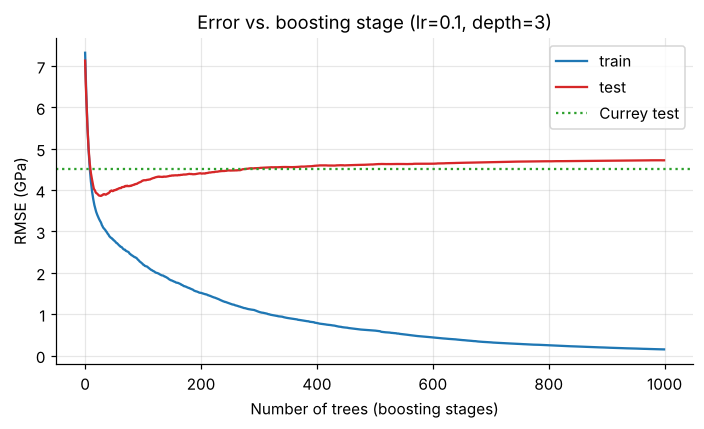

Best test-RMSE stage: 28


In [10]:
big = GradientBoostingRegressor(n_estimators=1000, learning_rate=0.1, max_depth=3, random_state=SEED).fit(X_tr, y_tr)
tr_err = [np.sqrt(mean_squared_error(y_tr, p)) for p in big.staged_predict(X_tr)]
te_err = [np.sqrt(mean_squared_error(y_te, p)) for p in big.staged_predict(X_te)]
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(tr_err, label="train"); ax.plot(te_err, label="test", color="C3")
ax.axhline(np.sqrt(mean_squared_error(y_te, cur_te)), ls=":", color="C2", label="Currey test")
ax.set(xlabel="Number of trees (boosting stages)", ylabel="RMSE (GPa)",
       title="Error vs. boosting stage (lr=0.1, depth=3)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG/"03_staged_error.png", dpi=200); plt.show()
print("Best test-RMSE stage:", int(np.argmin(te_err)) + 1)

## 6. Effect of hyperparameters on RMSE and $R^2$
Each parameter is varied alone with the others held at the tuned values; RMSE/$R^2$ are reported on train, 5-fold CV (within training set) and test.

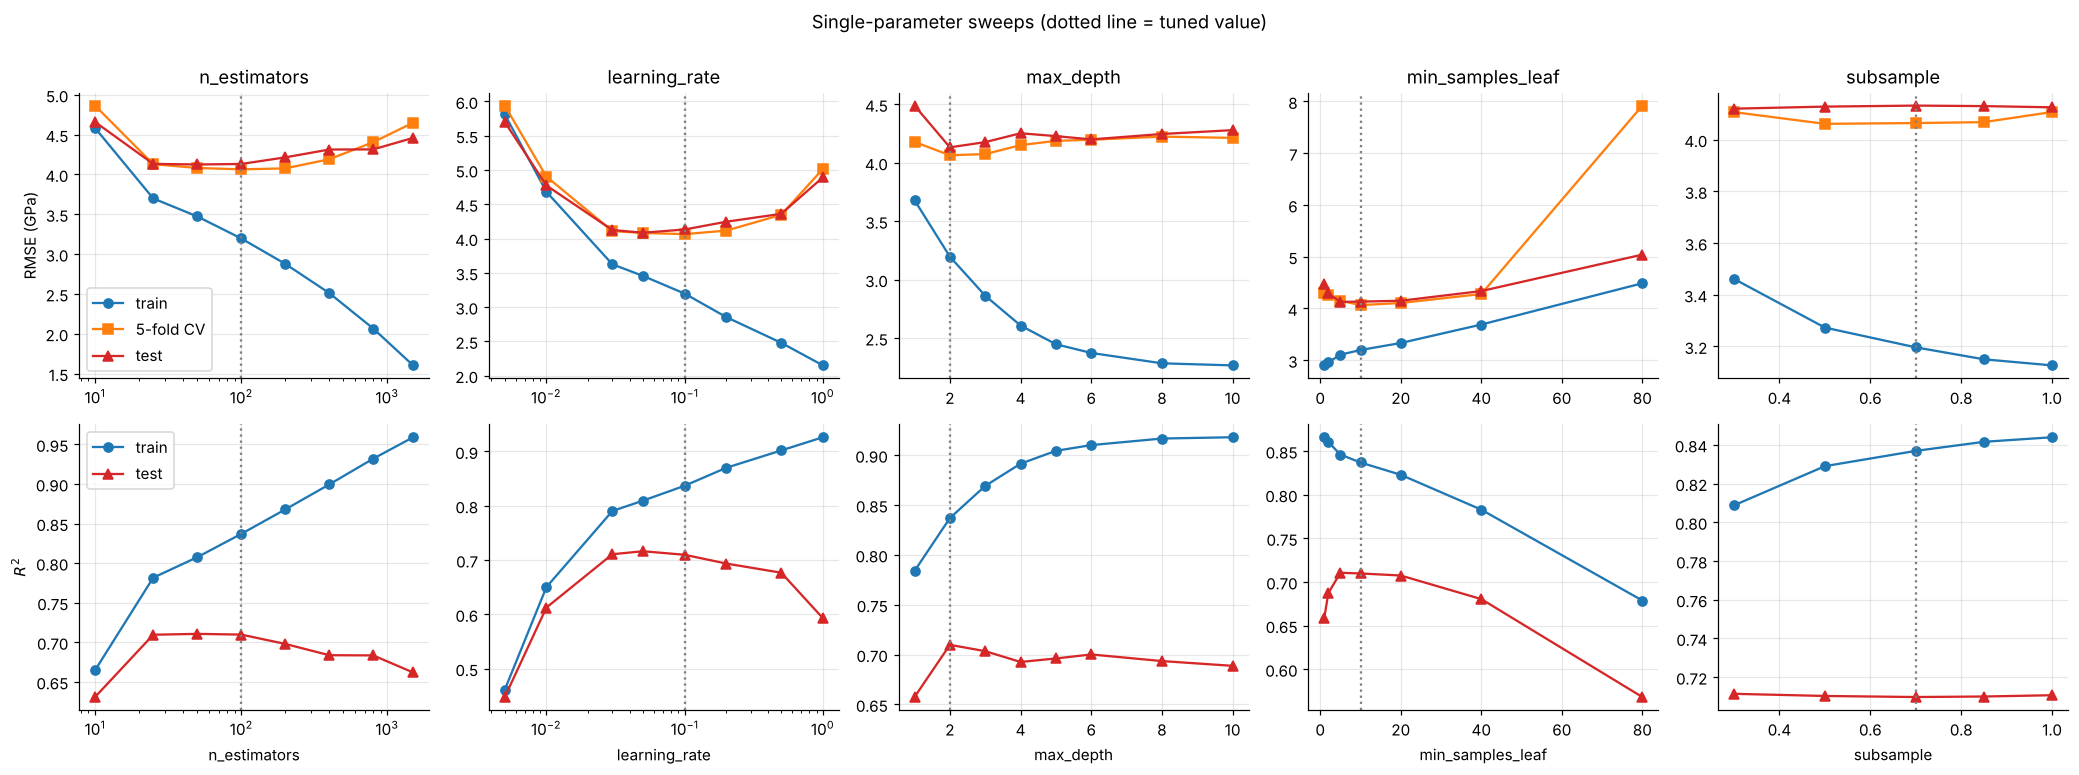

In [11]:
best = grid.best_params_
sweeps = {
    "n_estimators":     [10, 25, 50, 100, 200, 400, 800, 1500],
    "learning_rate":    [0.005, 0.01, 0.03, 0.05, 0.1, 0.2, 0.5, 1.0],
    "max_depth":        [1, 2, 3, 4, 5, 6, 8, 10],
    "min_samples_leaf": [1, 2, 5, 10, 20, 40, 80],
    "subsample":        [0.3, 0.5, 0.7, 0.85, 1.0],
}
rows = []
for name, values in sweeps.items():
    for v in values:
        params = {**best, name: v}
        m = GradientBoostingRegressor(random_state=SEED, **params).fit(X_tr, y_tr)
        cv_rmse = -cross_val_score(GradientBoostingRegressor(random_state=SEED, **params), X_tr, y_tr,
                                   cv=cv, scoring="neg_root_mean_squared_error").mean()
        rows.append({"param": name, "value": v,
                     "train_RMSE": np.sqrt(mean_squared_error(y_tr, m.predict(X_tr))),
                     "cv_RMSE": cv_rmse,
                     "test_RMSE": np.sqrt(mean_squared_error(y_te, m.predict(X_te))),
                     "train_R2": r2_score(y_tr, m.predict(X_tr)),
                     "test_R2": r2_score(y_te, m.predict(X_te))})
sweep_df = pd.DataFrame(rows)
sweep_df.to_csv(FIG/"param_sweeps.csv", index=False)

fig, axes = plt.subplots(2, 5, figsize=(19, 7))
for j, name in enumerate(sweeps):
    s = sweep_df[sweep_df.param == name]
    a = axes[0, j]
    a.plot(s.value, s.train_RMSE, "o-", label="train"); a.plot(s.value, s.cv_RMSE, "s-", label="5-fold CV")
    a.plot(s.value, s.test_RMSE, "^-", label="test", color="C3")
    a.axvline(best[name], color="grey", ls=":"); a.set(title=name, ylabel="RMSE (GPa)" if j == 0 else "")
    b = axes[1, j]
    b.plot(s.value, s.train_R2, "o-", label="train"); b.plot(s.value, s.test_R2, "^-", label="test", color="C3")
    b.axvline(best[name], color="grey", ls=":"); b.set(xlabel=name, ylabel="$R^2$" if j == 0 else "")
    if name in ("n_estimators", "learning_rate"):
        a.set_xscale("log"); b.set_xscale("log")
axes[0, 0].legend(); axes[1, 0].legend()
fig.suptitle("Single-parameter sweeps (dotted line = tuned value)", y=1.0)
fig.tight_layout(); fig.savefig(FIG/"04_param_sweeps.png", dpi=200); plt.show()

### Interaction between `learning_rate` and `n_estimators`
These two trade off against each other (shrinkage): a smaller learning rate needs proportionally more trees.

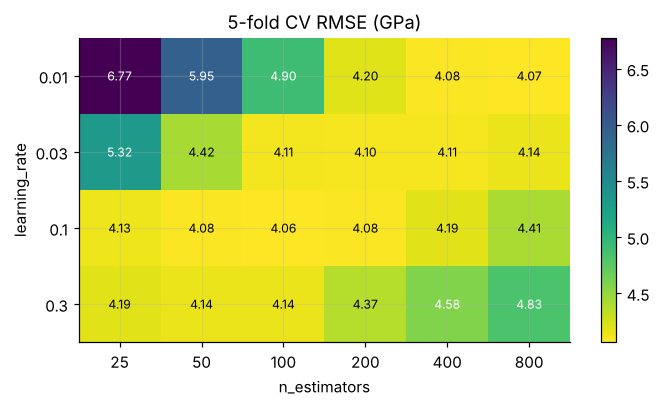

In [12]:
lrs = [0.01, 0.03, 0.1, 0.3]
ns = [25, 50, 100, 200, 400, 800]
H = np.zeros((len(lrs), len(ns)))
for i, lr in enumerate(lrs):
    for k, n in enumerate(ns):
        H[i, k] = -cross_val_score(GradientBoostingRegressor(random_state=SEED, **{**best, "learning_rate": lr, "n_estimators": n}),
                                   X_tr, y_tr, cv=cv, scoring="neg_root_mean_squared_error").mean()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
im = ax.imshow(H, cmap="viridis_r", aspect="auto")
ax.set_xticks(range(len(ns)), ns); ax.set_yticks(range(len(lrs)), lrs)
for i in range(len(lrs)):
    for k in range(len(ns)):
        ax.text(k, i, f"{H[i,k]:.2f}", ha="center", va="center", color="w" if H[i,k] > H.mean() else "k", fontsize=8)
ax.set(xlabel="n_estimators", ylabel="learning_rate", title="5-fold CV RMSE (GPa)")
fig.colorbar(im, ax=ax); fig.tight_layout(); fig.savefig(FIG/"05_lr_vs_n.png", dpi=200); plt.show()

## 7. Interpretation — which input matters, and in which direction?

In [13]:
imp = pd.DataFrame({"impurity importance": gbr.feature_importances_}, index=features)
perm = permutation_importance(gbr, X_te, y_te, n_repeats=50, random_state=SEED, scoring="r2")
imp["permutation ΔR² (test)"] = perm.importances_mean
imp["perm. std"] = perm.importances_std
imp.round(3)

,impurity importance,permutation ΔR² (test),perm. std
Ca_mg_g,0.665,0.696,0.111
Vf,0.335,0.325,0.049


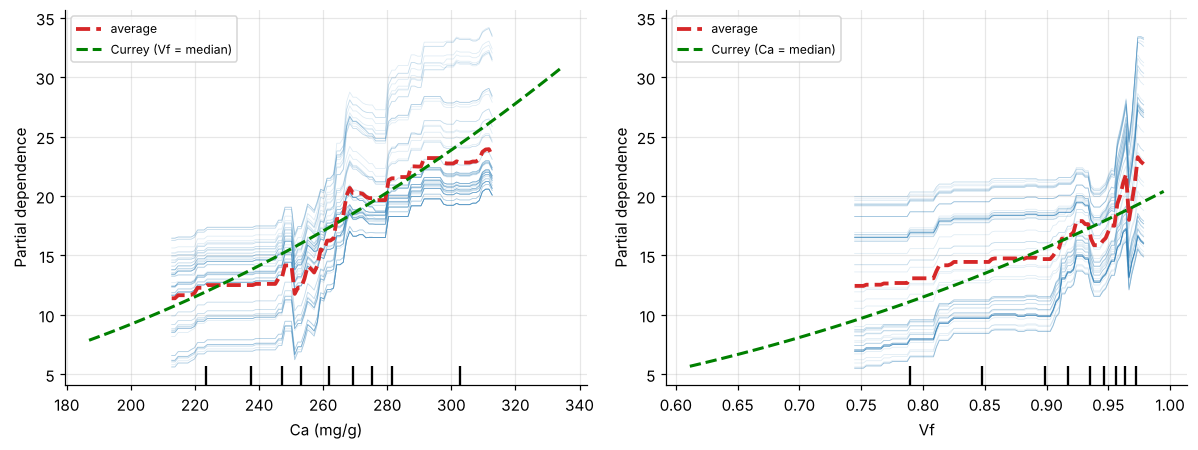

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
PartialDependenceDisplay.from_estimator(gbr, X_tr, [0, 1], feature_names=["Ca (mg/g)", "Vf"],
                                        kind="both", subsample=80, random_state=SEED, ax=ax,
                                        ice_lines_kw={"alpha": 0.15}, pd_line_kw={"color": "C3", "lw": 2.5})
# overlay Currey's partial effect (other input at training median)
ca_g = np.linspace(X_tr[:, 0].min(), X_tr[:, 0].max(), 100)
vf_g = np.linspace(X_tr[:, 1].min(), X_tr[:, 1].max(), 100)
fig.axes[0].plot(ca_g, currey((ca_g, np.median(X_tr[:, 1])), *p_cur), "g--", lw=2, label="Currey (Vf = median)")
fig.axes[1].plot(vf_g, currey((np.median(X_tr[:, 0]), vf_g), *p_cur), "g--", lw=2, label="Currey (Ca = median)")
for a in fig.axes[:2]: a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG/"06_partial_dependence.png", dpi=200); plt.show()

## 8. Did we need to normalise the data?
Decision trees split on thresholds of one feature at a time, so any **monotonic** rescaling of an input (standardisation, min–max, log) leaves the set of possible splits unchanged. We verify this directly by fitting the tuned model with and without `StandardScaler`.

In [15]:
raw = GradientBoostingRegressor(random_state=SEED, **best).fit(X_tr, y_tr)
scaled = make_pipeline(StandardScaler(), GradientBoostingRegressor(random_state=SEED, **best)).fit(X_tr, y_tr)
logX = GradientBoostingRegressor(random_state=SEED, **best).fit(np.log(X_tr), y_tr)
print("Raw    test RMSE: %.6f" % np.sqrt(mean_squared_error(y_te, raw.predict(X_te))))
print("Scaled test RMSE: %.6f" % np.sqrt(mean_squared_error(y_te, scaled.predict(X_te))))
print("log(X) test RMSE: %.6f" % np.sqrt(mean_squared_error(y_te, logX.predict(np.log(X_te)))))
print("Max |difference| raw vs scaled predictions: %.2e GPa" % np.abs(raw.predict(X_te) - scaled.predict(X_te)).max())

Raw    test RMSE: 4.131733
Scaled test RMSE: 4.131733
log(X) test RMSE: 4.131733
Max |difference| raw vs scaled predictions: 0.00e+00 GPa


## 9. Behaviour far outside the data range (extrapolation)
A tree ensemble is piecewise constant: beyond the last split threshold its prediction is **flat**. The Currey power law, by contrast, continues to grow (or collapse) according to its exponents.

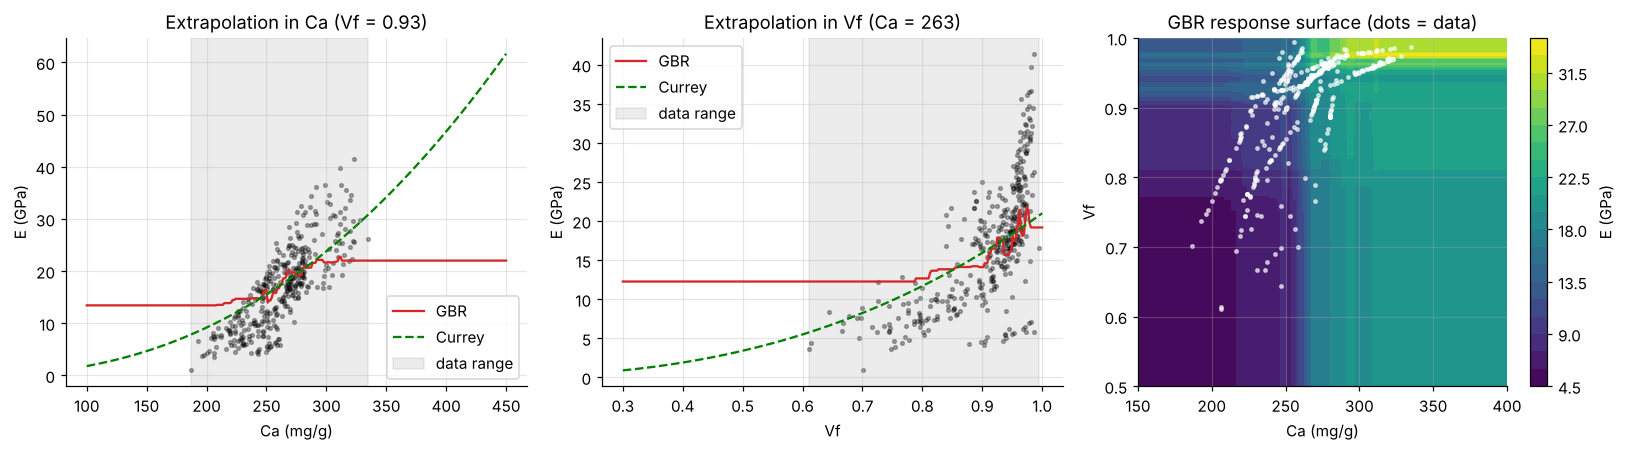

,Ca,Vf,GBR E (GPa),Currey E (GPa)
0,150.0,0.60,5.52,1.46
1,186.9,0.70,5.52,3.68
2,334.8,0.99,31.33,35.91
3,400.0,0.99,31.33,54.53
4,450.0,1.00,31.33,73.82


In [16]:
ca_ext = np.linspace(100, 450, 300)
vf_ext = np.linspace(0.3, 1.0, 300)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
vf_med, ca_med = np.median(X[:, 1]), np.median(X[:, 0])
ax[0].plot(ca_ext, gbr.predict(np.c_[ca_ext, np.full_like(ca_ext, vf_med)]), color="C3", label="GBR")
ax[0].plot(ca_ext, currey((ca_ext, vf_med), *p_cur), "g--", label="Currey")
ax[0].axvspan(X[:, 0].min(), X[:, 0].max(), color="grey", alpha=.15, label="data range")
ax[0].scatter(X[:, 0], y, s=6, alpha=.3, color="k")
ax[0].set(xlabel="Ca (mg/g)", ylabel="E (GPa)", title=f"Extrapolation in Ca (Vf = {vf_med:.2f})"); ax[0].legend()
ax[1].plot(vf_ext, gbr.predict(np.c_[np.full_like(vf_ext, ca_med), vf_ext]), color="C3", label="GBR")
ax[1].plot(vf_ext, currey((ca_med, vf_ext), *p_cur), "g--", label="Currey")
ax[1].axvspan(X[:, 1].min(), X[:, 1].max(), color="grey", alpha=.15, label="data range")
ax[1].scatter(X[:, 1], y, s=6, alpha=.3, color="k")
ax[1].set(xlabel="Vf", ylabel="E (GPa)", title=f"Extrapolation in Vf (Ca = {ca_med:.0f})"); ax[1].legend()
CA, VF = np.meshgrid(np.linspace(150, 400, 200), np.linspace(0.5, 1.0, 200))
Z = gbr.predict(np.c_[CA.ravel(), VF.ravel()]).reshape(CA.shape)
cs = ax[2].contourf(CA, VF, Z, levels=20, cmap="viridis")
ax[2].scatter(X[:, 0], X[:, 1], s=5, color="w", alpha=.6)
ax[2].set(xlabel="Ca (mg/g)", ylabel="Vf", title="GBR response surface (dots = data)")
fig.colorbar(cs, ax=ax[2], label="E (GPa)")
fig.tight_layout(); fig.savefig(FIG/"07_extrapolation.png", dpi=200); plt.show()

probe = np.array([[150, 0.6], [186.9, 0.70], [334.8, 0.99], [400, 0.99], [450, 1.0]])
pd.DataFrame({"Ca": probe[:, 0], "Vf": probe[:, 1],
              "GBR E (GPa)": gbr.predict(probe).round(2),
              "Currey E (GPa)": currey((probe[:, 0], probe[:, 1]), *p_cur).round(2)})

## 10. Discussion

**Are the trends consistent with Currey's physical model?** Yes, qualitatively. The partial-dependence curves show $E$ increasing with both $Ca$ and $V_f$ (apart from small local wiggles that are noise fits), and the response surface (Section 9) shows the two inputs act jointly — the highest $E$ occurs only when both are high — as in the multiplicative power law $E = a\,Ca^{b}V_f^{c}$. Calcium is the dominant input (higher impurity and permutation importance), consistent with mineralisation being the primary stiffness determinant and with the stronger E–Ca correlation (r ≈ 0.81 vs 0.68 for Vf). Unlike Currey's smooth curve, the GBR curve is a staircase and saturates at the data edges.

**How good is the fit?** Tuned GBR: test RMSE 4.13 GPa, $R^2$ = 0.71, versus 4.50 GPa / 0.66 for the 3-parameter Currey fit — a modest gain. The default GBR over-fits (train $R^2$ 0.92 vs test 0.70); tuning toward shallower trees (`max_depth=2`), larger leaves (`min_samples_leaf=10`) and row subsampling closed that gap. The remaining error is largely irreducible with only $Ca$ and $V_f$: the scatter plot of the input space shows distinct streaks (different specimen groups/sources) with different $E$ at the same composition.

**Hyperparameter effects:** more trees or a higher learning rate always lower training RMSE but test/CV RMSE is U-shaped (best ≈ 50–200 trees at lr 0.05–0.1; lr ≤ 0.01 under-fits with 100 trees, lr = 1 over-fits). Depth 1 (additive stumps, no interaction) under-fits; depth ≥ 4 over-fits. Very small leaves over-fit and very large leaves (≥ 40) under-fit. `subsample` has little effect here.

**Did we need to normalise?** No. Tree splits are invariant to monotonic transforms of the inputs; standardised, raw, and log-transformed inputs give the same test error (Section 8). The target was not transformed either.

**Strengths:** no assumed functional form; captures non-linearity and interactions automatically; insensitive to feature scaling and robust to outliers in inputs; built-in feature importance; good accuracy on tabular data with modest $n$.
**Weaknesses:** many hyperparameters that interact (learning rate × n_estimators, depth); can over-fit (training RMSE → 0 while test RMSE plateaus); piecewise-constant, non-smooth output (no physically meaningful derivatives such as $\partial E/\partial Ca$); no physical parameters to interpret; no native uncertainty estimate (quantile loss could be used); sequential training is slower than random forests.

**Higher dimensionality:** many more compositional inputs are handled naturally — trees pick the informative features and ignore weak ones, and importance rankings help with feature selection, but more data are needed to avoid over-fitting. `GradientBoostingRegressor` predicts a single output, so multiple mechanical properties (E, strength, toughness) need one model per output (`MultiOutputRegressor`) or `RegressorChain` to exploit correlations between outputs.

**Far outside the data range:** poorly. Predictions become constant beyond the outermost split (Section 9), so the model can neither predict the continued rise of $E$ with mineral content nor the collapse at high porosity. A physical model such as Currey's is far preferable for extrapolation; GBR should be trusted only inside the convex hull of the training data.